# UW-IBM QML Hackathon: Classical vs Projected Quantum Kernels

Cells from "Start From Here" onward are IBM/UW's starter cells, kept unchanged. Anything marked OUR ADDITION is ours.

Task: predict CAR T-cell cytotoxicity (high vs low) from 4 motif slots. We compare an RBF-SVM on classical one-hot features against an RBF-SVM on pre-computed quantum projections.

In [ ]:
# OUR ADDITION: check the kernel is the project environment
import sys, platform
print("Python:    ", sys.version.split()[0], "|", platform.system())
print("Executable:", sys.executable)


Python:     3.11.9 | Windows
Executable: c:\Users\bhara\Documents\hackathons\quantum-pqk-car-t-hackathon\qpqk-env\Scripts\python.exe


# Start From Here

Starter notebook for the UW–IBM Quantum Machine Learning Hackathon. Read the companion notebook `UW-IBM_QML_Hackathon.ipynb`to understand the hackathon objectives. This notebook handles environment setup, data preprocessing, and a quick baseline so you can hit the ground running:

1. Install + imports (Sections 1, 2)
2. Download + preprocess the CAR T-cell data (Section 3)
3. Quick baseline — classical vs. quantum-projected SVM with F1 comparison and kernel heatmaps (Section 4)
4. Pointer to the IBM PQK tutorial for Tracks 1, 2, and Bonus

After running every cell here, you'll have the same variables the IBM PQK tutorial expects from Step 2 onwards, plus a ΔF1 result you can sanity-check against the tutorial. From there you copy cells from the tutorial to build out your own analyses for the hackathon prompt's challenge tracks.

## 1. Environment Setup

### Install required packages

Run this once per environment. If you're on Colab or a fresh JupyterLab session, this will take ~2 minutes. If everything is already installed, pip will skip ahead.

In [2]:
!pip install -U "qiskit[visualization]" qiskit-ibm-runtime \
    category-encoders==2.8.1 numpy==2.3.2 pandas==2.3.2 \
    scikit-learn tqdm==4.67.1

### Import libraries

All imports for the whole notebook live in this single cell. If you run a later cell and get a `NameError`, come back and re-run this one.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import f1_score, classification_report
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

from scipy.linalg import inv, sqrtm

# Qiskit (only needed for Track 2D real-hardware comparison)
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import (
    Batch,
    EstimatorOptions,
    EstimatorV2 as Estimator,
    QiskitRuntimeService,
)

import tqdm

# Global random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. IBM Quantum Account Setup

> **Team account**
>
> For this hackathon you'll use a shared **team account** with 25 minutes of QPU time. To access it you need an API key which you received today.
>
> If your team runs out of QPU time, contact your IBM mentor (Sophy) or a UW admin (Kristen)

> **⚠️ Back up your results before May 16, 2026 ⚠️**
>
> The hackathon team accounts will be deleted on May 16th, 2026. Save your job results to disk before then — see [Retrieve job results](https://quantum.cloud.ibm.com/docs/en/guides/save-jobs#retrieve-job-results-from-ibm-quantum) and [Save results to disk](https://quantum.cloud.ibm.com/docs/en/guides/save-jobs#save-results-to-disk).

### Enter your credentials

Replace the placeholders below with your team's API key and CRN.

In [4]:
API_KEY = "YOUR_API_KEY_HERE"

# Uncomment to save credentials once (then comment back out):
# QiskitRuntimeService.save_account(
#     token=API_KEY,
#     overwrite=True,
# )

# Uncomment to load and verify your service connection:
# service = QiskitRuntimeService(token=API_KEY)
# print("Available backends:", [b.name for b in service.backends()])

In [33]:
#service = QiskitRuntimeService(token=api, instance=crn_open)
service= QiskitRuntimeService()
print("Available backends:", [b.name for b in service.backends()])

Available backends: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']


## 3. Download and preprocess the CAR T-cell data

The dataset is hosted in the official Qiskit documentation repo. We download four files:

- `train_data.csv`, `test_data.csv` — raw motif IDs and cytotoxicity scores
- `projections_train.csv`, `projections_test.csv` — pre-computed 180-dim quantum projections from IBM Heron R2 hardware

After downloading, we sanitize the files if needed (some shipped versions have a UTF-8 BOM and wrapped quotes), then preprocess them using the **exact pipeline from the IBM PQK tutorial** — same `preprocess_data` / `data_encoder` functions, same `args` dict, same π/2 scaling — so your numbers align with the paper (Utro et al. 2025) and the official tutorial.

In [6]:
def download_pqk_dataset(data_dir="data_tutorial/pqk"):
    """Download the four CSV files from the Qiskit documentation repo."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)

    base_url = (
        "https://raw.githubusercontent.com/Qiskit/documentation/main/"
        "datasets/tutorials/pqk"
    )
    files = [
        "train_data.csv",
        "test_data.csv",
        "projections_train.csv",
        "projections_test.csv",
    ]

    for filename in files:
        url = f"{base_url}/{filename}"
        dest = data_dir / filename
        print(f"  {filename} ...", end=" ", flush=True)
        urllib.request.urlretrieve(url, dest)
        print(f"✓ ({dest.stat().st_size:,} bytes)")

    print(f"\nAll files saved to {data_dir}/")
    return data_dir


DATA_DIR = download_pqk_dataset()

  train_data.csv ... ✓ (5,012 bytes)
  test_data.csv ... ✓ (2,194 bytes)
  projections_train.csv ... ✓ (779,730 bytes)
  projections_test.csv ... ✓ (335,529 bytes)

All files saved to data_tutorial\pqk/


In [7]:
# ---------------------------------------------------------------------------
# Helper: sanitize CSV files into well-formed ones.
#
# The data files in this dataset sometimes ship with two quirks that confuse pd.read_csv:
#   - a UTF-8 BOM at the start
#   - every line wrapped in an extra pair of double quotes, so the whole row is parsed as one column of 172/74 strings (motif CSVs only)
#   - whitespace-separated floats instead of commas (projection CSVs only)
#
# We detect and repair these in place so the IBM tutorial code below works unmodified. Already well-formed files are left alone.
# ---------------------------------------------------------------------------
def sanitize_csv_files(data_dir):
    """Normalize quirky CSV files to well-formed UTF-8 comma-separated CSVs."""
    data_dir = Path(data_dir)

    # Motif files: strip BOM and outer line-wrap quotes if present.
    for name in ["train_data.csv", "test_data.csv"]:
        path = data_dir / name
        if not path.exists():
            continue
        with open(path, "rb") as f:
            raw = f.read()
        text = raw.decode("utf-8-sig")
        lines = text.replace("\r\n", "\n").strip().split("\n")
        wrapped = all(
            len(L) >= 2 and L.startswith('"') and L.endswith('"') for L in lines
        )
        if wrapped:
            lines = [L[1:-1] for L in lines]
        cleaned = "\n".join(lines) + "\n"
        if cleaned.encode("utf-8") != raw:
            path.write_text(cleaned, encoding="utf-8")
            print(f"  Sanitized {name}")

    # Projection files: convert whitespace-separated to comma-separated if needed.
    for name in ["projections_train.csv", "projections_test.csv"]:
        path = data_dir / name
        if not path.exists():
            continue
        with open(path, "rb") as f:
            head = f.read(2048)
        text_head = head.decode("utf-8-sig", errors="replace")
        first_line = text_head.split("\n")[0]
        # If the first line has many whitespace-separated floats and no commas,
        # it\'s the whitespace-separated format.
        if "," not in first_line and len(first_line.split()) > 10:
            # Whitespace-separated → reload with pandas sep=r"\s+" and rewrite as CSV.
            from io import StringIO
            with open(path, "rb") as f:
                text = f.read().decode("utf-8-sig")
            df = pd.read_csv(StringIO(text), sep=r"\s+", header=None, engine="python")
            df.to_csv(path, index=False, header=False)
            print(f"  Sanitized {name}")


sanitize_csv_files(DATA_DIR)


# ---------------------------------------------------------------------------
# The two preprocessing functions below are the IBM PQK tutorial code, 
# kept intentionally close to the original so your results align with the paper (Utro et al. 2025) and the tutorial. See:
#   https://quantum.cloud.ibm.com/docs/en/tutorials/projected-quantum-kernels
# ---------------------------------------------------------------------------
def preprocess_data(dir_root, args):
    """
    Preprocess the training and test data.
    Tutorial-exact: load CSVs, normalize motif ID 17 → 14, force canonical
    column names, optionally filter by spacer-motif rules, binarize labels
    at the cytotoxicity threshold, shift motif IDs to start at 0.
    """
    # Read from the csv files
    train_data = pd.read_csv(
        os.path.join(dir_root, args["file_train_data"]),
        encoding="unicode_escape",
        sep=",",
    )
    test_data = pd.read_csv(
        os.path.join(dir_root, args["file_test_data"]),
        encoding="unicode_escape",
        sep=",",
    )

    # Fix the last motif ID
    train_data[train_data == 17] = 14
    train_data.columns = [
        "Cell Number",
        "motif",
        "motif.1",
        "motif.2",
        "motif.3",
        "motif.4",
        "Nalm 6 Cytotoxicity",
    ]
    test_data[test_data == 17] = 14
    test_data.columns = [
        "Cell Number",
        "motif",
        "motif.1",
        "motif.2",
        "motif.3",
        "motif.4",
        "Nalm 6 Cytotoxicity",
    ]

    # Adjust motif at the third position
    if args["filter_for_spacer_motif_third_position"]:
        train_data = train_data[
            (train_data["motif.2"] == 14) | (train_data["motif.2"] == 0)
        ]
        test_data = test_data[
            (test_data["motif.2"] == 14) | (test_data["motif.2"] == 0)
        ]

    train_data = train_data[
        args["motifs_to_use"] + [args["label_name"], "Cell Number"]
    ]
    test_data = test_data[
        args["motifs_to_use"] + [args["label_name"], "Cell Number"]
    ]

    # Adjust motif at the last position
    if not args["allow_spacer_motif_last_position"]:
        last_motif = args["motifs_to_use"][len(args["motifs_to_use"]) - 1]
        train_data = train_data[
            (train_data[last_motif] != 14) & (train_data[last_motif] != 0)
        ]
        test_data = test_data[
            (test_data[last_motif] != 14) & (test_data[last_motif] != 0)
        ]

    # Get the labels
    train_labels = np.array(train_data[args["label_name"]])
    test_labels = np.array(test_data[args["label_name"]])

    # For the classification task use the threshold to binarize labels
    train_labels[train_labels > args["label_binarization_threshold"]] = 1
    train_labels[train_labels < 1] = args["min_label_value"]
    test_labels[test_labels > args["label_binarization_threshold"]] = 1
    test_labels[test_labels < 1] = args["min_label_value"]

    # Reduce data to just the motifs of interest
    train_data = train_data[args["motifs_to_use"]]
    test_data = test_data[args["motifs_to_use"]]

    # Get the class and motif counts
    min_class = np.min(np.unique(np.concatenate([train_data, test_data])))
    max_class = np.max(np.unique(np.concatenate([train_data, test_data])))

    num_class = max_class - min_class + 1
    num_motifs = len(args["motifs_to_use"])
    print(f"  max_class:min_class:num_class = {max_class}:{min_class}:{num_class}")
    print(f"  Train: {len(train_data)} samples, Test: {len(test_data)} samples")

    train_data = train_data - min_class
    test_data = test_data - min_class

    return (
        train_data,
        test_data,
        train_labels,
        test_labels,
        num_class,
        num_motifs,
    )


def data_encoder(args, train_data, test_data, num_class, num_motifs):
    """
    Use one-hot or binary encoding for classical data representation.
    Tutorial-exact.
    """
    if args["encoder"] == "one-hot":
        train_data = np.eye(num_class)[train_data]
        test_data = np.eye(num_class)[test_data]

        train_data = train_data.reshape(
            train_data.shape[0], train_data.shape[1] * train_data.shape[2]
        )
        test_data = test_data.reshape(
            test_data.shape[0], test_data.shape[1] * test_data.shape[2]
        )

    elif args["encoder"] == "binary":
        import category_encoders as ce
        encoder = ce.BinaryEncoder()
        base_array = np.unique(np.concatenate([train_data, test_data]))
        base = pd.DataFrame(base_array).astype("category")
        base.columns = ["motif"]
        for motif_name in args["motifs_to_use"][1:]:
            base[motif_name] = base.loc[:, "motif"]
        encoder.fit(base)

        train_data = encoder.transform(train_data.astype("category"))
        test_data = encoder.transform(test_data.astype("category"))

        train_data = np.reshape(
            train_data.values, (train_data.shape[0], num_motifs, -1)
        )
        test_data = np.reshape(
            test_data.values, (test_data.shape[0], num_motifs, -1)
        )

        train_data = train_data.reshape(
            train_data.shape[0], train_data.shape[1] * train_data.shape[2]
        )
        test_data = test_data.reshape(
            test_data.shape[0], test_data.shape[1] * test_data.shape[2]
        )

    else:
        raise ValueError("Invalid encoding type.")

    return train_data, test_data


# ---------------------------------------------------------------------------
# Run preprocessing using the tutorial's exact args.
# ---------------------------------------------------------------------------
args = {
    "file_train_data": "train_data.csv",
    "file_test_data": "test_data.csv",
    "motifs_to_use": ["motif", "motif.1", "motif.2", "motif.3"],
    "label_name": "Nalm 6 Cytotoxicity",
    "label_binarization_threshold": 0.62,
    "filter_for_spacer_motif_third_position": False,
    "allow_spacer_motif_last_position": True,
    "min_label_value": -1,
    "encoder": "one-hot",
}

# preprocess_data returns motif-ID DataFrames; we keep these around for Track 2C.
train_motifs, test_motifs, train_labels, test_labels, num_class, num_motifs = (
    preprocess_data(dir_root=str(DATA_DIR), args=args)
)
NUM_CLASS = int(num_class)
NUM_MOTIFS = int(num_motifs)

# data_encoder turns motif IDs into one-hot vectors.
train_data, test_data = data_encoder(args, train_motifs, test_motifs, num_class, num_motifs)

# Tutorial step: scale the active one-hot entries to π/2.
angle = np.pi / 2
tmp = pd.DataFrame(train_data).astype("float64"); tmp[tmp == 1] = angle
train_data = tmp.values
tmp = pd.DataFrame(test_data).astype("float64"); tmp[tmp == 1] = angle
test_data = tmp.values

print(f"  train_data: {train_data.shape}")
print(f"  test_data:  {test_data.shape}")

  Sanitized projections_train.csv
  Sanitized projections_test.csv
  max_class:min_class:num_class = 14:0:15
  Train: 172 samples, Test: 74 samples
  train_data: (172, 60)
  test_data:  (74, 60)


### Load the pre-computed quantum projections

The IBM PQK tutorial spends roughly 80 minutes of QPU time generating the 180-dim projections. We use the pre-computed CSVs that shipped with the tutorial repo, so you can skip directly to analysis.

After this cell runs, you'll have all the variables the IBM tutorial expects from Step 2 onwards:

| Variable | Shape | Source |
|---|---|---|
| `train_data` | `(172, 60)` | One-hot motifs × π/2 |
| `test_data` | `(74, 60)` | Same encoding |
| `train_labels` | `(172,)` | Binary {−1, +1} |
| `test_labels` | `(74,)` | Same |
| `projections_train` | `(172, 180)` | Pre-computed quantum 1-RDMs |
| `projections_test` | `(74, 180)` | Same |
| `num_class` | `15` | Number of motif IDs |
| `num_motifs` | `4` | Number of motif positions |

If you want to generate your own projections on a real QPU as part of the hackathon, follow the tutorial's Step 3 ("Execute using Qiskit primitives"). You'll need an active IBM Quantum account and ~80 minutes of queue + execution time on a Heron-class backend.

In [8]:
# Load the pre-computed 180-dim quantum projections.
# Headers may or may not be present depending on which version of the file
# you have; we read with header=0 first and detect the no-header case by
# checking that the first row is numeric.
def _load_projections(path):
    df = pd.read_csv(path)
    # If the header row turned out to be data (first column not parseable as
    # column-name-like), reload without a header.
    try:
        _ = df.columns.astype(float)
        df = pd.read_csv(path, header=None)
    except (ValueError, TypeError):
        pass
    df.columns = [f"q{i}" for i in range(df.shape[1])]
    return df


projections_train = _load_projections(DATA_DIR / "projections_train.csv")
projections_test = _load_projections(DATA_DIR / "projections_test.csv")

# Sanity check — all four feature matrices and the label arrays must agree.
assert len(train_data) == len(projections_train) == len(train_labels), (
    f"Train length mismatch: train_data={len(train_data)}, "
    f"projections_train={len(projections_train)}, labels={len(train_labels)}"
)
assert len(test_data) == len(projections_test) == len(test_labels), (
    f"Test length mismatch: test_data={len(test_data)}, "
    f"projections_test={len(projections_test)}, labels={len(test_labels)}"
)

print(f"train_data:        {train_data.shape},   test_data:        {test_data.shape}")
print(f"projections_train: {projections_train.shape}, projections_test: {projections_test.shape}")
print(f"train_labels:      {train_labels.shape},        test_labels:      {test_labels.shape}")
print(f"Class balance (train): {dict(zip(*np.unique(train_labels, return_counts=True)))}")
print(f"Class balance (test):  {dict(zip(*np.unique(test_labels, return_counts=True)))}")


train_data:        (172, 60),   test_data:        (74, 60)
projections_train: (172, 180), projections_test: (74, 180)
train_labels:      (172,),        test_labels:      (74,)
Class balance (train): {np.float64(-1.0): np.int64(83), np.float64(1.0): np.int64(89)}
Class balance (test):  {np.float64(-1.0): np.int64(35), np.float64(1.0): np.int64(39)}


## 4. Quick baseline

This section trains a classical and a quantum-projected RBF-SVM on the data you just loaded and compares them. It uses the same hyperparameter grid as the IBM PQK tutorial (13 × 12 = 156 grid points, 10-fold CV) so your numbers will match the tutorial's headline result.

Runtime: ~1–2 minutes on a modern laptop.

After this you have the **Track 0 baseline result** plus two visuals to look at, and you can move on to designing your own Track 0 / 1 / 2 / Bonus experiments by copying cells from the tutorial.

In [9]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, classification_report

# Hyperparameter grid matched to the IBM PQK tutorial scale.
# 13 C values × 12 γ values = 156 grid points, 10-fold CV.
PARAM_GRID = {
    "C":     [0.1, 0.5, 1, 2.5, 5, 7.5, 8.5, 10, 10.75, 15, 25, 50, 100],
    "gamma": ["auto", "scale", 0.001, 0.005, 0.01, 0.02, 0.04, 0.05,
              0.1, 0.25, 0.5, 1],
}
cv = StratifiedKFold(n_splits=10)

# Classical SVM on raw one-hot features
print("Training classical SVM (~30s)...")
svm_classical = GridSearchCV(
    SVC(kernel="rbf"), PARAM_GRID, cv=cv,
    scoring="f1_weighted", n_jobs=-1,
).fit(train_data, train_labels)
pred_classical = svm_classical.predict(test_data)
f1_classical = f1_score(test_labels, pred_classical, average="weighted")

# Quantum-projected SVM on the pre-computed 180-dim projections
print("Training quantum-projected SVM (~30s)...")
svm_quantum = GridSearchCV(
    SVC(kernel="rbf"), PARAM_GRID, cv=cv,
    scoring="f1_weighted", n_jobs=-1,
).fit(projections_train, train_labels)
pred_quantum = svm_quantum.predict(projections_test)
f1_quantum = f1_score(test_labels, pred_quantum, average="weighted")

print()
print(f"Classical: best params = {svm_classical.best_params_}, test F1 = {f1_classical:.4f}")
print(f"Quantum:   best params = {svm_quantum.best_params_}, test F1 = {f1_quantum:.4f}")
print(f"ΔF1 (quantum − classical) = {f1_quantum - f1_classical:+.4f}")


Training classical SVM (~30s)...
Training quantum-projected SVM (~30s)...

Classical: best params = {'C': 10.75, 'gamma': 0.04}, test F1 = 0.7423
Quantum:   best params = {'C': 8.5, 'gamma': 0.01}, test F1 = 0.8108
ΔF1 (quantum − classical) = +0.0686


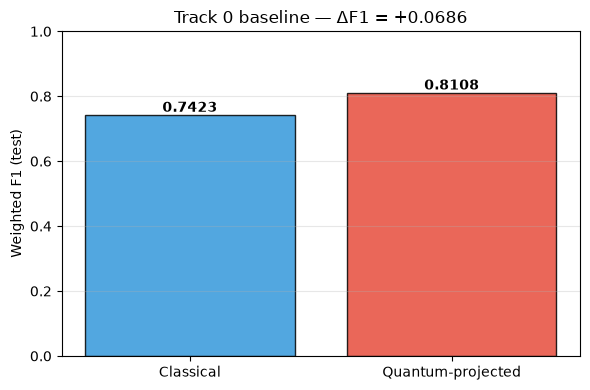

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Classical", "Quantum-projected"],
    [f1_classical, f1_quantum],
    color=["#3498db", "#e74c3c"], alpha=0.85, edgecolor="black",
)
for b, score in zip(bars, [f1_classical, f1_quantum]):
    ax.text(b.get_x() + b.get_width() / 2, score + 0.01,
            f"{score:.4f}", ha="center", fontweight="bold")
ax.set_ylabel("Weighted F1 (test)")
ax.set_ylim(0, 1)
ax.set_title(f"Track 0 baseline — ΔF1 = {f1_quantum - f1_classical:+.4f}")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


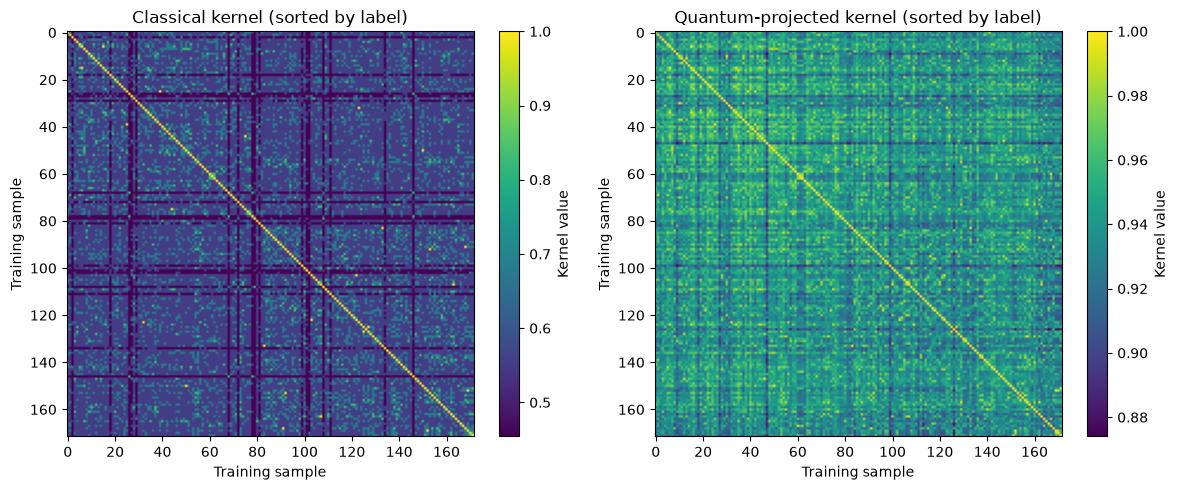

Look for block-diagonal structure (high within-class similarity). Which kernel shows it more clearly?


In [11]:
from sklearn.metrics.pairwise import rbf_kernel


def resolve_gamma(gamma, X):
    """Convert sklearn's 'scale'/'auto' strings to a numeric γ for rbf_kernel."""
    Xarr = np.asarray(X)
    if gamma == "scale":
        return 1.0 / (Xarr.shape[1] * Xarr.var())
    if gamma == "auto":
        return 1.0 / Xarr.shape[1]
    return gamma


gamma_c = resolve_gamma(svm_classical.best_params_["gamma"], train_data)
gamma_q = resolve_gamma(svm_quantum.best_params_["gamma"], projections_train)

K_c = rbf_kernel(train_data, gamma=gamma_c)
K_q = rbf_kernel(projections_train, gamma=gamma_q)

# Sort rows and columns by label to make any class structure visible
sort_idx = np.argsort(train_labels)
K_c_sorted = K_c[sort_idx][:, sort_idx]
K_q_sorted = K_q[sort_idx][:, sort_idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, K, title in zip(
    axes,
    [K_c_sorted, K_q_sorted],
    ["Classical kernel (sorted by label)",
     "Quantum-projected kernel (sorted by label)"],
):
    im = ax.imshow(K, cmap="viridis", aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Training sample")
    ax.set_ylabel("Training sample")
    plt.colorbar(im, ax=ax, label="Kernel value")
plt.tight_layout()
plt.show()

print("Look for block-diagonal structure (high within-class similarity)."
      " Which kernel shows it more clearly?")


## You're ready — continue from the IBM PQK tutorial

You now have a working baseline (the section above). To go further on Tracks 1 (Anatomy), 2 (Robustness), or Bonus (geometric difference), open the IBM PQK tutorial notebook (`projected-quantum-kernels.ipynb`) and copy cells into this notebook (or a scratch notebook in the same kernel session).

### Which tutorial cells to copy, and which to SKIP

The tutorial mixes "explain how to compute the projections" with "use the pre-computed projections". You already have the projections — you should **skip the cells that re-compute them**. Here's a precise guide:

| Tutorial cell | Content | What to do |
|---|---|---|
| **Cell 20** | `feature_dimension = train_data.shape[1]` + ZZFeatureMap embedding | Copy if you want to use the ZZ feature map |
| **Cell 22** | Same as 20 but with 1D-Heisenberg Hamiltonian embedding | Copy (optional, alternative embedding) |
| **Cells 27, 29, 31, 32, 34** | Backend selection, single-sample QPU smoke test | Skip unless you want to verify QPU access |
| **Cells 37–44** | Loop over all 172 training samples on QPU (~80 min) | Skip — these regenerate the projections we already loaded |
| **Cell 51** | `projections_train = np.loadtxt("projections_train.txt")` | SKIP — will fail. This loads cached `.txt` files that don't ship with the dataset; we already loaded the `.csv` versions above into `projections_train` and `projections_test`. |
| **Cells 54, 56** | Train classical + quantum SVMs with GridSearchCV | ✅ Copy — this is your Track 0 baseline |
| **Cells 59, 61, 62** | Geometric difference $g$ + model complexities | ✅ Copy — this is the Bonus track |

### For Tracks 1 and 2 (Anatomy / Robustness)

Design your own slicing and subsetting code on top of `projections_train`, `projections_test`, `train_data`, `test_data`, and the motif metadata in `train_motifs`, `test_motifs`. Useful slicing patterns:

```python
# By measurement basis — projections_train is laid out as <X> | <Y> | <Z>
basis_X = projections_train.iloc[:, 0:60]      # ⟨X⟩ on 60 qubits
basis_Y = projections_train.iloc[:, 60:120]    # ⟨Y⟩
basis_Z = projections_train.iloc[:, 120:180]   # ⟨Z⟩

# By motif position — every 15-column block within each basis
# (position 1 = cols 0-14, position 2 = cols 15-29, etc., per basis)
```

For the problem statement, hypotheses, and presentation requirements, see the companion `UW-IBM_QML_Hackathon.ipynb` prompt notebook.

---
# OUR ADDITIONS

Everything below this line is our own work. IBM/UW's starter cells above are unchanged.

## Track 0: rigor upgrades

The baseline gives one test F1 from one split of 74 samples. A 6.9 point gap there is only about 5 samples. Before building on it, we do three things:

1. Save the baseline figures to `results/` and put both kernels on a comparable scale. IBM's heatmaps use a separate colour scale per panel, which hides how different the value ranges are.
2. Measure block structure with a number: average similarity within a class vs across classes, in standard deviation units.
3. Re-estimate F1 with repeated cross-validation and test whether the gap is statistically meaningful (next group of cells).

In [12]:
# OUR ADDITION: shared setup for our extra analyses (IBM's variables stay untouched)
P_train = np.asarray(projections_train)   # IBM's projections are DataFrames, arrays are safer for indexing
P_test = np.asarray(projections_test)

C_C = svm_classical.best_params_["C"]
C_Q = svm_quantum.best_params_["C"]
GAMMA_C = resolve_gamma(svm_classical.best_params_["gamma"], train_data)
GAMMA_Q = resolve_gamma(svm_quantum.best_params_["gamma"], P_train)

if Path.cwd().name == "notebooks":
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print(f"Classical: C={C_C}, gamma={GAMMA_C:.5f}, grid-search CV F1 = {svm_classical.best_score_:.4f}")
print(f"Quantum:   C={C_Q}, gamma={GAMMA_Q:.5f}, grid-search CV F1 = {svm_quantum.best_score_:.4f}")
print(f"Test F1:   classical {f1_classical:.4f}, quantum {f1_quantum:.4f}")
print(f"Figures will be saved to: {RESULTS_DIR}")

Classical: C=10.75, gamma=0.04000, grid-search CV F1 = 0.7830
Quantum:   C=8.5, gamma=0.01000, grid-search CV F1 = 0.6980
Test F1:   classical 0.7423, quantum 0.8108
Figures will be saved to: c:\Users\bhara\Documents\hackathons\quantum-pqk-car-t-hackathon\results


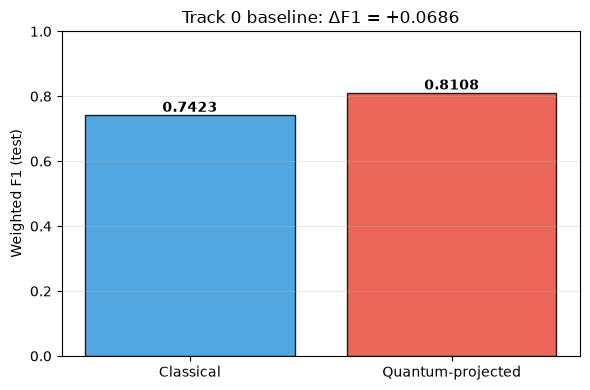

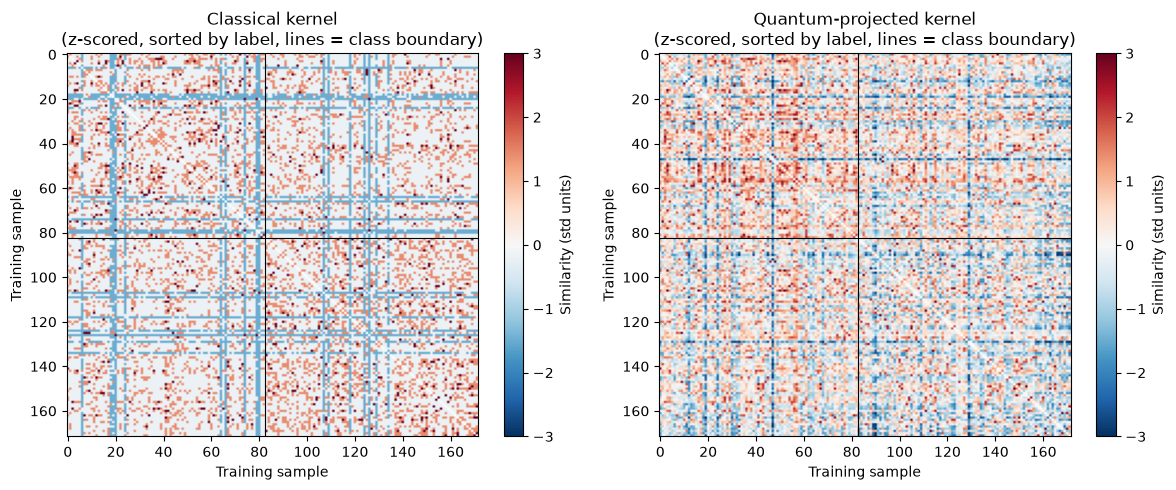

Classical          within-class = 0.5733, cross-class = 0.5607, contrast = +0.166 std
Quantum-projected  within-class = 0.9403, cross-class = 0.9394, contrast = +0.052 std
Contrast above 0 means same-class pairs are more similar than cross-class pairs.


In [13]:
# OUR ADDITION: baseline figures saved to results/, plus a number for block structure
Kc = rbf_kernel(train_data, gamma=GAMMA_C)
Kq = rbf_kernel(P_train, gamma=GAMMA_Q)

order = np.argsort(train_labels, kind="stable")
boundary = int((train_labels == -1).sum())   # where the two classes meet after sorting

# 1) F1 bar chart (same as IBM's, but saved)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Classical", "Quantum-projected"], [f1_classical, f1_quantum],
              color=["#3498db", "#e74c3c"], alpha=0.85, edgecolor="black")
for bar, score in zip(bars, [f1_classical, f1_quantum]):
    ax.text(bar.get_x() + bar.get_width() / 2, score + 0.01, f"{score:.4f}",
            ha="center", fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Weighted F1 (test)")
ax.set_title(f"Track 0 baseline: ΔF1 = {f1_quantum - f1_classical:+.4f}")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "track0_f1_bars.png", dpi=150, bbox_inches="tight")
plt.show()

# 2) Both kernels on a comparable scale (z-scored over off-diagonal entries)
def zscore_offdiag(K):
    off = ~np.eye(len(K), dtype=bool)
    Z = (K - K[off].mean()) / K[off].std()
    np.fill_diagonal(Z, np.nan)   # hide the diagonal, it is always 1
    return Z

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, K, title in zip(axes, [Kc, Kq], ["Classical kernel", "Quantum-projected kernel"]):
    Z = zscore_offdiag(K)[order][:, order]
    im = ax.imshow(Z, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    ax.axhline(boundary - 0.5, color="black", lw=0.8)
    ax.axvline(boundary - 0.5, color="black", lw=0.8)
    ax.set_title(f"{title}\n(z-scored, sorted by label, lines = class boundary)")
    ax.set_xlabel("Training sample")
    ax.set_ylabel("Training sample")
    plt.colorbar(im, ax=ax, label="Similarity (std units)")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "track0_kernel_heatmaps_zscored.png", dpi=150, bbox_inches="tight")
plt.show()

# 3) Block structure as a number
def block_contrast(K, y):
    n = len(y)
    off = ~np.eye(n, dtype=bool)
    same = (y[:, None] == y[None, :]) & off
    diff = (y[:, None] != y[None, :])
    within = K[same].mean()
    cross = K[diff].mean()
    return within, cross, (within - cross) / K[off].std()

for name, K in [("Classical", Kc), ("Quantum-projected", Kq)]:
    within, cross, contrast = block_contrast(K, train_labels)
    print(f"{name:18s} within-class = {within:.4f}, cross-class = {cross:.4f}, contrast = {contrast:+.3f} std")
print("Contrast above 0 means same-class pairs are more similar than cross-class pairs.")

### Is the test-set gap real?

The two checks disagree. On the 74 test samples quantum wins by 6.9 F1 points. In the grid search CV on the 172 training samples quantum loses (0.698 vs 0.783). The cells below look at this from three angles:

1. Repeated 5-fold CV with the tuned hyperparameters (20 repeats, 100 folds per model, identical folds for both models).
2. A paired sign-flip permutation test on the fold differences.
3. A McNemar test on the 74 test predictions.

Caveat: every fold reuses the same 172 samples, so the folds are not independent. The p-values are rough guides, not exact probabilities.

In [14]:
# OUR ADDITION: repeated cross-validation with the tuned hyperparameters
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=RANDOM_STATE)

model_c = SVC(kernel="rbf", C=C_C, gamma=GAMMA_C)
model_q = SVC(kernel="rbf", C=C_Q, gamma=GAMMA_Q)

# same cv object and same seed, so both models see identical folds
scores_c = cross_val_score(model_c, train_data, train_labels, cv=cv_rep, scoring="f1_weighted")
scores_q = cross_val_score(model_q, P_train, train_labels, cv=cv_rep, scoring="f1_weighted")
diffs = scores_q - scores_c

rng = np.random.default_rng(RANDOM_STATE)
boot_means = rng.choice(diffs, size=(5000, len(diffs)), replace=True).mean(axis=1)
low, high = np.percentile(boot_means, [2.5, 97.5])

print(f"Folds per model: {len(scores_c)} (5 folds x 20 repeats)")
print(f"Classical CV F1: {scores_c.mean():.4f} (std {scores_c.std():.4f})")
print(f"Quantum CV F1:   {scores_q.mean():.4f} (std {scores_q.std():.4f})")
print(f"Mean paired difference (quantum - classical): {diffs.mean():+.4f}")
print(f"95% bootstrap interval for the difference: [{low:+.4f}, {high:+.4f}]")
print(f"Quantum better in {(diffs > 0).sum()} of {len(diffs)} folds")

Folds per model: 100 (5 folds x 20 repeats)
Classical CV F1: 0.7406 (std 0.0709)
Quantum CV F1:   0.6919 (std 0.0680)
Mean paired difference (quantum - classical): -0.0486
95% bootstrap interval for the difference: [-0.0637, -0.0333]
Quantum better in 23 of 100 folds


Observed mean difference: -0.0486
p-value using all 100 folds:      0.0001
p-value using 20 repeat averages: 0.0002


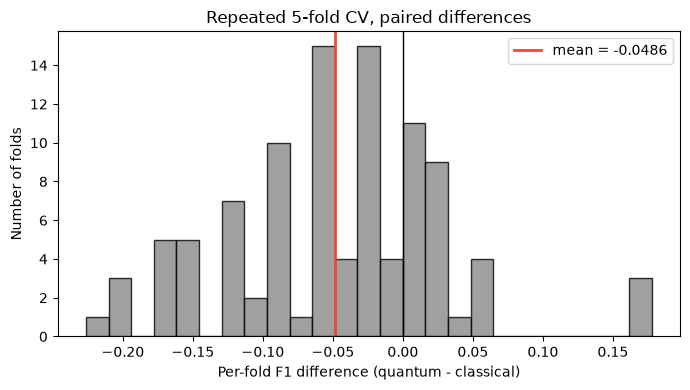

In [15]:
# OUR ADDITION: paired sign-flip permutation test on the fold differences
N_PERM = 10000
observed = diffs.mean()

signs = rng.choice([-1, 1], size=(N_PERM, len(diffs)))
perm_means = (signs * diffs).mean(axis=1)
p_fold = (np.sum(np.abs(perm_means) >= abs(observed)) + 1) / (N_PERM + 1)

# more cautious version: average the 5 folds of each repeat first, leaving 20 values
rep_diffs = diffs.reshape(20, 5).mean(axis=1)
signs_rep = rng.choice([-1, 1], size=(N_PERM, len(rep_diffs)))
perm_rep = (signs_rep * rep_diffs).mean(axis=1)
p_rep = (np.sum(np.abs(perm_rep) >= abs(rep_diffs.mean())) + 1) / (N_PERM + 1)

print(f"Observed mean difference: {observed:+.4f}")
print(f"p-value using all 100 folds:      {p_fold:.4f}")
print(f"p-value using 20 repeat averages: {p_rep:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(diffs, bins=25, color="#888888", edgecolor="black", alpha=0.8)
ax.axvline(0, color="black", lw=1)
ax.axvline(observed, color="#e74c3c", lw=2, label=f"mean = {observed:+.4f}")
ax.set_xlabel("Per-fold F1 difference (quantum - classical)")
ax.set_ylabel("Number of folds")
ax.set_title("Repeated 5-fold CV, paired differences")
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_DIR / "track0_cv_paired_differences.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# OUR ADDITION: McNemar test on the 74 test predictions (same samples, two models)
from scipy.stats import binomtest

correct_c = (pred_classical == test_labels)
correct_q = (pred_quantum == test_labels)

both_right = int((correct_c & correct_q).sum())
both_wrong = int((~correct_c & ~correct_q).sum())
only_classical = int((correct_c & ~correct_q).sum())
only_quantum = int((~correct_c & correct_q).sum())

result = binomtest(only_quantum, only_quantum + only_classical, 0.5)

print(f"Both right: {both_right}, both wrong: {both_wrong}")
print(f"Only classical right: {only_classical}")
print(f"Only quantum right:   {only_quantum}")
print(f"Exact McNemar p-value (two-sided): {result.pvalue:.4f}")

Both right: 49, both wrong: 8
Only classical right: 6
Only quantum right:   11
Exact McNemar p-value (two-sided): 0.3323


### Nested cross-validation

The tuned C and gamma above were picked using the same training data we then cross-validated on, which flatters both models. Nested CV fixes this. For each outer fold, a fresh grid search (IBM's PARAM_GRID) runs only on the outer training part, and the winning model is scored on the held-out outer fold it never saw.

Setup: 5 outer folds x 3 repeats = 15 outer folds, inner 5-fold CV for tuning. Both models use identical outer folds.

In [17]:
# OUR ADDITION: nested CV, hyperparameters tuned inside each training fold
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

nested_c = []
nested_q = []

print("Running nested CV (should take a few minutes at most)...")
for fold_number, (train_idx, test_idx) in enumerate(outer_cv.split(train_data, train_labels)):
    for X, store in [(train_data, nested_c), (P_train, nested_q)]:
        search = GridSearchCV(SVC(kernel="rbf"), PARAM_GRID, cv=inner_cv,
                              scoring="f1_weighted", n_jobs=-1)
        search.fit(X[train_idx], train_labels[train_idx])
        pred = search.predict(X[test_idx])
        store.append(f1_score(train_labels[test_idx], pred, average="weighted"))
    print(f"  outer fold {fold_number + 1} of 15 done")

nested_c = np.array(nested_c)
nested_q = np.array(nested_q)
nested_diffs = nested_q - nested_c

boot_means = rng.choice(nested_diffs, size=(5000, len(nested_diffs)), replace=True).mean(axis=1)
low, high = np.percentile(boot_means, [2.5, 97.5])

signs = rng.choice([-1, 1], size=(N_PERM, len(nested_diffs)))
perm_means = (signs * nested_diffs).mean(axis=1)
p_nested = (np.sum(np.abs(perm_means) >= abs(nested_diffs.mean())) + 1) / (N_PERM + 1)

print()
print(f"Classical nested CV F1: {nested_c.mean():.4f} (std {nested_c.std():.4f})")
print(f"Quantum nested CV F1:   {nested_q.mean():.4f} (std {nested_q.std():.4f})")
print(f"Mean paired difference (quantum - classical): {nested_diffs.mean():+.4f}")
print(f"95% bootstrap interval: [{low:+.4f}, {high:+.4f}]")
print(f"Quantum better in {(nested_diffs > 0).sum()} of {len(nested_diffs)} outer folds")
print(f"Sign-flip p-value: {p_nested:.4f}")

Running nested CV (should take a few minutes at most)...
  outer fold 1 of 15 done
  outer fold 2 of 15 done
  outer fold 3 of 15 done
  outer fold 4 of 15 done
  outer fold 5 of 15 done
  outer fold 6 of 15 done
  outer fold 7 of 15 done
  outer fold 8 of 15 done
  outer fold 9 of 15 done
  outer fold 10 of 15 done
  outer fold 11 of 15 done
  outer fold 12 of 15 done
  outer fold 13 of 15 done
  outer fold 14 of 15 done
  outer fold 15 of 15 done

Classical nested CV F1: 0.7503 (std 0.0508)
Quantum nested CV F1:   0.7070 (std 0.0649)
Mean paired difference (quantum - classical): -0.0433
95% bootstrap interval: [-0.0778, -0.0101]
Quantum better in 5 of 15 outer folds
Sign-flip p-value: 0.0297


### Bonus: geometric difference and model complexity

The geometric difference g measures how differently the quantum-projected kernel organizes the training data compared to the classical kernel. Near 1 means the two kernels look alike, so classical ML should keep up. Near sqrt(N) means they differ a lot, so a quantum advantage is possible in principle.

We follow IBM's tutorial code: lambda = 1 / C of the best classical SVM, the matrix infinity norm (`ord=np.inf`), and SVM predictions as the labels in the complexity formula. As a cross-check we also report g with the spectral norm, and model complexity with the true labels.

Huang et al. say an advantage needs g close to sqrt(N), and a classical model complexity on the order of N while the quantum one is much smaller.

In [18]:
# OUR ADDITION: geometric difference g and model complexities
def geometric_difference(Kc, Kq, lam_c, norm_type):
    Kc_sqrt = sqrtm(Kc)
    Kq_sqrt = sqrtm(Kq)
    Kc_inv = inv(Kc + lam_c * np.eye(len(Kc)))
    middle = Kq_sqrt @ Kc_sqrt @ Kc_inv @ Kc_inv @ Kc_sqrt @ Kq_sqrt
    return np.sqrt(np.real(np.linalg.norm(middle, ord=norm_type)))

def model_complexity(K, lam, labels):
    n = len(labels)
    K_inv = inv(K + lam * np.eye(n))
    label_matrix = np.outer(labels, labels)
    first = lam * np.sqrt(np.sum((K_inv @ K_inv) * label_matrix) / n)
    second = np.sqrt(np.sum((K_inv @ K @ K_inv) * label_matrix) / n)
    return first + second

n_train = len(train_labels)
sqrt_n = np.sqrt(n_train)
lam_c = 1 / C_C
lam_q = 1 / C_Q

g_inf = geometric_difference(Kc, Kq, lam_c, np.inf)    # IBM tutorial choice
g_spec = geometric_difference(Kc, Kq, lam_c, 2)        # spectral norm cross-check

print(f"N = {n_train}, sqrt(N) = {sqrt_n:.4f}")
print(f"g (matrix inf-norm, tutorial): {g_inf:.4f}   g / sqrt(N) = {g_inf / sqrt_n:.4f}")
print(f"g (spectral norm, check):      {g_spec:.4f}   g / sqrt(N) = {g_spec / sqrt_n:.4f}")

pred_c = svm_classical.predict(train_data)
pred_q = svm_quantum.predict(P_train)

s_c = model_complexity(Kc, lam_c, pred_c)
s_q = model_complexity(Kq, lam_q, pred_q)
s_c_true = model_complexity(Kc, lam_c, train_labels)
s_q_true = model_complexity(Kq, lam_q, train_labels)

print()
print(f"Model complexity with SVM predictions (tutorial): s_c = {s_c:.4f}, s_q = {s_q:.4f}")
print(f"Model complexity with true labels (check):        s_c = {s_c_true:.4f}, s_q = {s_q_true:.4f}")
print(f"Compare with N = {n_train}. Advantage needs s_c near N and s_q much smaller.")

N = 172, sqrt(N) = 13.1149
g (matrix inf-norm, tutorial): 1.5440   g / sqrt(N) = 0.1177
g (spectral norm, check):      1.3591   g / sqrt(N) = 0.1036

Model complexity with SVM predictions (tutorial): s_c = 1.3578, s_q = 1.5806
Model complexity with true labels (check):        s_c = 1.6056, s_q = 1.7303
Compare with N = 172. Advantage needs s_c near N and s_q much smaller.


  N  g_mean  g_std  sqrt_N  g_over_sqrt_N
 34  1.3992 0.0136  5.8310         0.2400
 68  1.4582 0.0131  8.2462         0.1768
103  1.4971 0.0061 10.1489         0.1475
137  1.5165 0.0084 11.7047         0.1296
172  1.5440 0.0000 13.1149         0.1177


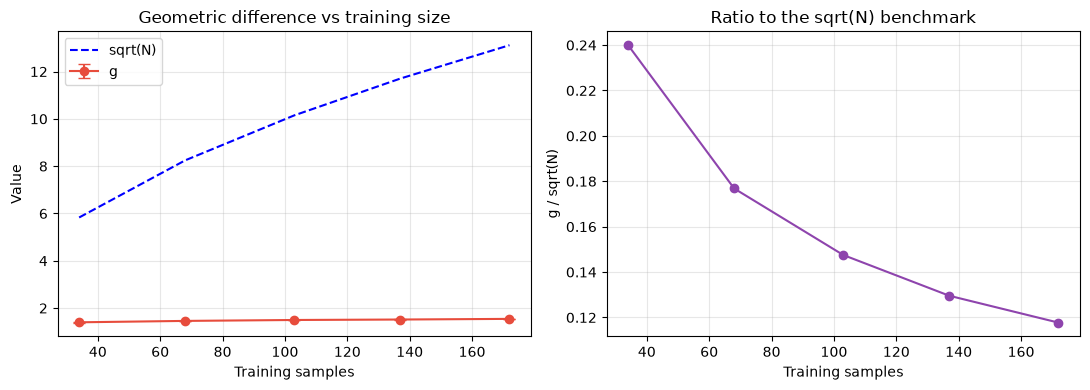

In [21]:
# OUR ADDITION: geometric difference at different training sizes (5 random subsamples each)
fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
rows = []

for frac in fractions:
    g_list = []
    if frac < 1.0:
        n_runs = 5
    else:
        n_runs = 1
    for seed in range(n_runs):
        if frac < 1.0:
            splitter = StratifiedShuffleSplit(n_splits=1, train_size=frac,
                                              random_state=RANDOM_STATE + seed)
            idx, _ = next(splitter.split(train_data, train_labels))
        else:
            idx = np.arange(len(train_labels))
        Kc_sub = rbf_kernel(train_data[idx], gamma=GAMMA_C)
        Kq_sub = rbf_kernel(P_train[idx], gamma=GAMMA_Q)
        g_list.append(geometric_difference(Kc_sub, Kq_sub, 1 / C_C, np.inf))
    n_sub = len(idx)
    rows.append({"N": n_sub, "g_mean": np.mean(g_list), "g_std": np.std(g_list),
                 "sqrt_N": np.sqrt(n_sub), "g_over_sqrt_N": np.mean(g_list) / np.sqrt(n_sub)})

g_table = pd.DataFrame(rows)
print(g_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(g_table["N"], g_table["g_mean"], yerr=g_table["g_std"],
                 marker="o", color="#e74c3c", capsize=4, label="g")
axes[0].plot(g_table["N"], g_table["sqrt_N"], "b--", label="sqrt(N)")
axes[0].set_xlabel("Training samples")
axes[0].set_ylabel("Value")
axes[0].set_title("Geometric difference vs training size")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(g_table["N"], g_table["g_over_sqrt_N"], marker="o", color="#8e44ad")
axes[1].set_xlabel("Training samples")
axes[1].set_ylabel("g / sqrt(N)")
axes[1].set_title("Ratio to the sqrt(N) benchmark")
axes[1].grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "bonus_geometric_difference.png", dpi=150, bbox_inches="tight")
plt.show()

## Track 2A: learning curves

Question: does the quantum encoding help more when training data is scarce, and does the classical model catch up as data grows?

Method: subsample the training set to 25%, 50% and 75% (stratified, 10 random seeds each) and use 100% as the reference. For each subsample, both models are tuned with IBM's grid search (10-fold CV) and scored on the fixed 74-sample test set. Both models see the identical subsample.

Caveats:
- The 100% point is a single run, so it has no error bar. It should match the baseline exactly (0.7423 and 0.8108).
- Subsamples overlap, especially at 75%, so the spread at high fractions understates the real uncertainty.
- The test set is small and flattered the quantum model at 100%, so read the differences as trends, not exact gaps.

In [22]:
# OUR ADDITION: Track 2A learning curves (this takes a few minutes)
fractions_2a = [0.25, 0.5, 0.75, 1.0]
n_seeds = 10
inner_10 = StratifiedKFold(n_splits=10)    # same as IBM's baseline, so 100% reproduces it

records = []
print("Running learning curves...")
for frac in fractions_2a:
    if frac < 1.0:
        runs = n_seeds
    else:
        runs = 1
    for seed in range(runs):
        if frac < 1.0:
            splitter = StratifiedShuffleSplit(n_splits=1, train_size=frac, random_state=seed)
            idx, _ = next(splitter.split(train_data, train_labels))
        else:
            idx = np.arange(len(train_labels))

        scores = []
        for X_tr, X_te in [(train_data, test_data), (P_train, P_test)]:
            search = GridSearchCV(SVC(kernel="rbf"), PARAM_GRID, cv=inner_10,
                                  scoring="f1_weighted", n_jobs=-1)
            search.fit(X_tr[idx], train_labels[idx])
            scores.append(f1_score(test_labels, search.predict(X_te), average="weighted"))

        records.append({"fraction": frac, "n": len(idx), "seed": seed,
                        "f1_classical": scores[0], "f1_quantum": scores[1]})
    print(f"  fraction {frac:.0%} done")

curve = pd.DataFrame(records)
curve["diff"] = curve["f1_quantum"] - curve["f1_classical"]
curve["quantum_better"] = (curve["diff"] > 0).astype(int)
curve.to_csv(RESULTS_DIR / "track2a_learning_curve_runs.csv", index=False)

full_row = curve[curve["fraction"] == 1.0].iloc[0]
print()
print(f"Check at 100%: classical {full_row['f1_classical']:.4f}, quantum {full_row['f1_quantum']:.4f} (baseline was 0.7423 and 0.8108)")

Running learning curves...
  fraction 25% done
  fraction 50% done
  fraction 75% done
  fraction 100% done

Check at 100%: classical 0.7423, quantum 0.8108 (baseline was 0.7423 and 0.8108)


     classical_mean  classical_std  quantum_mean  quantum_std  diff_mean  diff_std  quantum_wins  runs
n                                                                                                     
43           0.7266         0.0498        0.6868       0.0245    -0.0397    0.0640             3    10
86           0.7462         0.0420        0.7238       0.0677    -0.0223    0.0494             3    10
129          0.7626         0.0597        0.7028       0.0754    -0.0598    0.0702             1    10
172          0.7423         0.0000        0.8108       0.0000     0.0686    0.0000             1     1


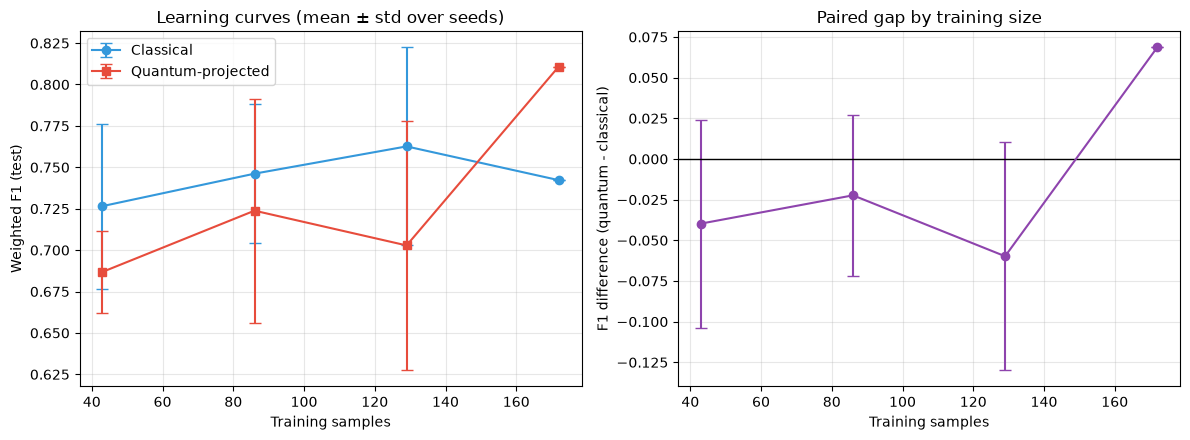

In [23]:
# OUR ADDITION: Track 2A summary table and figure
summary = curve.groupby("n").agg(
    classical_mean=("f1_classical", "mean"),
    classical_std=("f1_classical", "std"),
    quantum_mean=("f1_quantum", "mean"),
    quantum_std=("f1_quantum", "std"),
    diff_mean=("diff", "mean"),
    diff_std=("diff", "std"),
    quantum_wins=("quantum_better", "sum"),
    runs=("diff", "count"),
).fillna(0)
print(summary.round(4).to_string())

sizes = summary.index.values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].errorbar(sizes, summary["classical_mean"], yerr=summary["classical_std"],
                 marker="o", capsize=4, color="#3498db", label="Classical")
axes[0].errorbar(sizes, summary["quantum_mean"], yerr=summary["quantum_std"],
                 marker="s", capsize=4, color="#e74c3c", label="Quantum-projected")
axes[0].set_xlabel("Training samples")
axes[0].set_ylabel("Weighted F1 (test)")
axes[0].set_title("Learning curves (mean ± std over seeds)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].errorbar(sizes, summary["diff_mean"], yerr=summary["diff_std"],
                 marker="o", capsize=4, color="#8e44ad")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Training samples")
axes[1].set_ylabel("F1 difference (quantum - classical)")
axes[1].set_title("Paired gap by training size")
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(RESULTS_DIR / "track2a_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Track 2B: noise robustness

Question: how much noise can each encoding tolerate, and at what level does any quantum benefit vanish?

Method: add Gaussian noise to both feature sets, on train and test. The noise standard deviation is a multiple of each column's own standard deviation (levels 0, 0.1, 0.25, 0.5, 1 and 2). Scaling per column makes the classical (0 or pi/2 one-hot) and quantum (expectation values) features comparable, and the level-0 point is identical to the baseline. Each level uses 5 random seeds, with both models re-tuned on every run using IBM's grid and 10-fold CV. We report F1 on the fixed test set and the share of each model's own noise-free F1 that it keeps.

Caveat: the test set is small, so read the trends, not single numbers.

In [24]:
# OUR ADDITION: Track 2B noise robustness (takes a few minutes)
noise_levels = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0]    # noise std as a multiple of each column's std
n_noise_seeds = 5

col_std_c = train_data.std(axis=0)
col_std_q = P_train.std(axis=0)

records_noise = []
print("Running noise robustness...")
for level_index, level in enumerate(noise_levels):
    if level == 0.0:
        runs = 1
    else:
        runs = n_noise_seeds
    for seed in range(runs):
        rng_noise = np.random.default_rng([seed, level_index])
        scores = []
        for X_tr, X_te, col_std in [(train_data, test_data, col_std_c), (P_train, P_test, col_std_q)]:
            noisy_tr = X_tr + rng_noise.normal(0, 1, X_tr.shape) * col_std * level
            noisy_te = X_te + rng_noise.normal(0, 1, X_te.shape) * col_std * level
            search = GridSearchCV(SVC(kernel="rbf"), PARAM_GRID, cv=inner_10,
                                  scoring="f1_weighted", n_jobs=-1)
            search.fit(noisy_tr, train_labels)
            scores.append(f1_score(test_labels, search.predict(noisy_te), average="weighted"))
        records_noise.append({"noise": level, "seed": seed,
                              "f1_classical": scores[0], "f1_quantum": scores[1]})
    print(f"  noise level {level} done")

noise_curve = pd.DataFrame(records_noise)
noise_curve["diff"] = noise_curve["f1_quantum"] - noise_curve["f1_classical"]
noise_curve.to_csv(RESULTS_DIR / "track2b_noise_runs.csv", index=False)

zero_row = noise_curve[noise_curve["noise"] == 0.0].iloc[0]
print()
print(f"Check at noise 0: classical {zero_row['f1_classical']:.4f}, quantum {zero_row['f1_quantum']:.4f} (baseline was 0.7423 and 0.8108)")

Running noise robustness...
  noise level 0.0 done
  noise level 0.1 done
  noise level 0.25 done
  noise level 0.5 done
  noise level 1.0 done
  noise level 2.0 done

Check at noise 0: classical 0.7423, quantum 0.8108 (baseline was 0.7423 and 0.8108)


       classical_mean  classical_std  quantum_mean  quantum_std  diff_mean  classical_kept  quantum_kept
noise                                                                                                   
0.00           0.7423         0.0000        0.8108       0.0000     0.0686          1.0000        1.0000
0.10           0.8184         0.0209        0.7866       0.0200    -0.0319          1.1026        0.9701
0.25           0.8027         0.0121        0.7456       0.0497    -0.0571          1.0814        0.9195
0.50           0.7730         0.0636        0.7567       0.0332    -0.0162          1.0414        0.9333
1.00           0.6702         0.0701        0.6728       0.0509     0.0026          0.9029        0.8298
2.00           0.5764         0.0373        0.5890       0.0547     0.0125          0.7766        0.7264


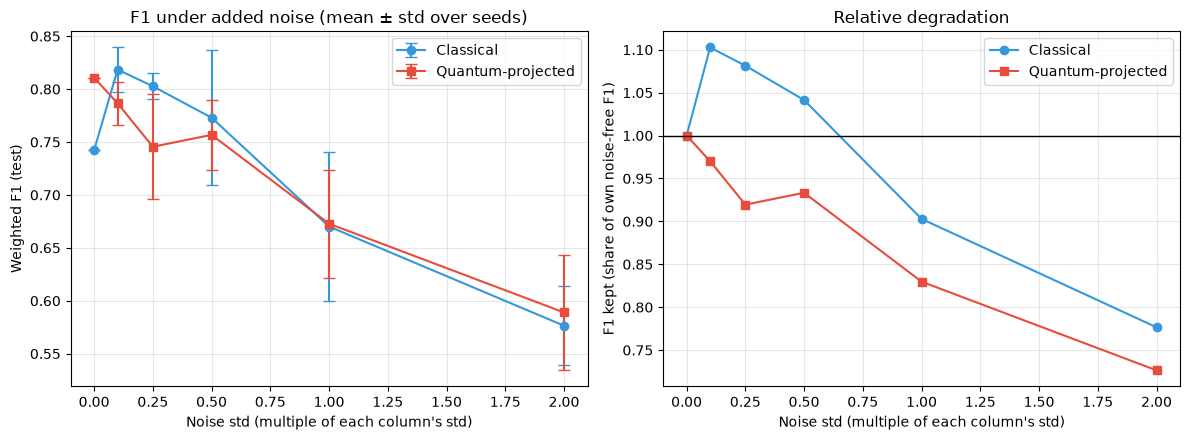

In [25]:
# OUR ADDITION: Track 2B summary table and figure
noise_summary = noise_curve.groupby("noise").agg(
    classical_mean=("f1_classical", "mean"),
    classical_std=("f1_classical", "std"),
    quantum_mean=("f1_quantum", "mean"),
    quantum_std=("f1_quantum", "std"),
    diff_mean=("diff", "mean"),
).fillna(0)
noise_summary["classical_kept"] = noise_summary["classical_mean"] / noise_summary["classical_mean"].iloc[0]
noise_summary["quantum_kept"] = noise_summary["quantum_mean"] / noise_summary["quantum_mean"].iloc[0]
print(noise_summary.round(4).to_string())

levels = noise_summary.index.values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].errorbar(levels, noise_summary["classical_mean"], yerr=noise_summary["classical_std"],
                 marker="o", capsize=4, color="#3498db", label="Classical")
axes[0].errorbar(levels, noise_summary["quantum_mean"], yerr=noise_summary["quantum_std"],
                 marker="s", capsize=4, color="#e74c3c", label="Quantum-projected")
axes[0].set_xlabel("Noise std (multiple of each column's std)")
axes[0].set_ylabel("Weighted F1 (test)")
axes[0].set_title("F1 under added noise (mean ± std over seeds)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(levels, noise_summary["classical_kept"], marker="o", color="#3498db", label="Classical")
axes[1].plot(levels, noise_summary["quantum_kept"], marker="s", color="#e74c3c", label="Quantum-projected")
axes[1].axhline(1.0, color="black", lw=1)
axes[1].set_xlabel("Noise std (multiple of each column's std)")
axes[1].set_ylabel("F1 kept (share of own noise-free F1)")
axes[1].set_title("Relative degradation")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(RESULTS_DIR / "track2b_noise_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

## Track 2C: does motif arrangement matter?

Question: does the task depend on combinations of motifs across positions, or only on which motifs appear in each position?

We shuffle the training motif IDs only (the test set stays original) and train classical models on the shuffled data:

- **shuffle_all**: each position column is permuted independently across all training rows (IBM's literal wording). This also breaks each position's link to the label, so it acts as a sanity floor near chance.
- **shuffle_within_class**: each column is permuted independently inside each label class. Per-position motif frequencies given the label are preserved, and only cross-position combinations are destroyed. This is the informative test for combinatorial structure.

We use 10 shuffle seeds, an RBF-SVM tuned with IBM's grid (10-fold CV), and a logistic regression on the same one-hot features as an additive reference with no interactions.

Limitation: this tests the structure of the task only. The quantum circuit cannot be re-run on shuffled data, so it says nothing directly about the quantum encoding.

In [27]:
# OUR ADDITION: Track 2C shuffling experiment (classical only)
from sklearn.linear_model import LogisticRegression

motif_train = train_motifs.values.astype(int)

def encode_motifs(motif_ids):
    one_hot = np.eye(NUM_CLASS)[motif_ids]
    return one_hot.reshape(len(motif_ids), -1) * (np.pi / 2)

# sanity check: our encoding must reproduce IBM's train_data
print("Encoding matches IBM's train_data:", np.allclose(encode_motifs(motif_train), train_data))

def shuffle_all(ids, rng):
    shuffled = ids.copy()
    for col in range(ids.shape[1]):
        shuffled[:, col] = rng.permutation(ids[:, col])
    return shuffled

def shuffle_within_class(ids, labels, rng):
    shuffled = ids.copy()
    for label in np.unique(labels):
        rows = np.where(labels == label)[0]
        for col in range(ids.shape[1]):
            shuffled[rows, col] = rng.permutation(ids[rows, col])
    return shuffled

LR_GRID = {"C": np.logspace(-3, 3, 13)}

n_shuffle_seeds = 10
records_shuffle = []
print("Running shuffle experiment (takes a few minutes)...")
for seed in range(n_shuffle_seeds):
    rng_shuffle = np.random.default_rng(seed)
    versions = {
        "original": motif_train,
        "shuffle_all": shuffle_all(motif_train, rng_shuffle),
        "shuffle_within_class": shuffle_within_class(motif_train, train_labels, rng_shuffle),
    }
    for name, ids in versions.items():
        if name == "original" and seed > 0:
            continue    # the original data does not change with the seed
        X_shuf = encode_motifs(ids)

        svm_search = GridSearchCV(SVC(kernel="rbf"), PARAM_GRID, cv=inner_10,
                                  scoring="f1_weighted", n_jobs=-1)
        svm_search.fit(X_shuf, train_labels)
        svm_f1 = f1_score(test_labels, svm_search.predict(test_data), average="weighted")

        lr_search = GridSearchCV(LogisticRegression(max_iter=5000), LR_GRID, cv=inner_10,
                                 scoring="f1_weighted", n_jobs=-1)
        lr_search.fit(X_shuf, train_labels)
        lr_f1 = f1_score(test_labels, lr_search.predict(test_data), average="weighted")

        records_shuffle.append({"variant": name, "seed": seed, "svm_f1": svm_f1, "lr_f1": lr_f1})
    print(f"  seed {seed + 1} of {n_shuffle_seeds} done")

Encoding matches IBM's train_data: True
Running shuffle experiment (takes a few minutes)...
  seed 1 of 10 done
  seed 2 of 10 done
  seed 3 of 10 done
  seed 4 of 10 done
  seed 5 of 10 done
  seed 6 of 10 done
  seed 7 of 10 done
  seed 8 of 10 done
  seed 9 of 10 done
  seed 10 of 10 done


                      svm_mean  svm_std  lr_mean  lr_std  runs
variant                                                       
original                0.7423   0.0000   0.7839  0.0000     1
shuffle_all             0.4773   0.1049   0.4517  0.0871    10
shuffle_within_class    0.8040   0.0249   0.7986  0.0195    10

shuffle_all            drop vs original: SVM +0.2649, logistic regression +0.3322
shuffle_within_class   drop vs original: SVM -0.0618, logistic regression -0.0146


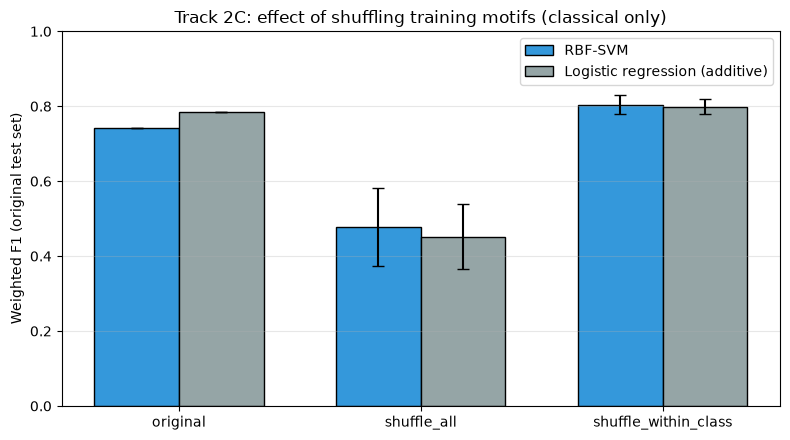

In [28]:
# OUR ADDITION: Track 2C summary table and figure
shuffle_df = pd.DataFrame(records_shuffle)
shuffle_df.to_csv(RESULTS_DIR / "track2c_shuffle_runs.csv", index=False)

order_variants = ["original", "shuffle_all", "shuffle_within_class"]
shuffle_summary = shuffle_df.groupby("variant").agg(
    svm_mean=("svm_f1", "mean"),
    svm_std=("svm_f1", "std"),
    lr_mean=("lr_f1", "mean"),
    lr_std=("lr_f1", "std"),
    runs=("svm_f1", "count"),
).fillna(0).loc[order_variants]
print(shuffle_summary.round(4).to_string())

base_svm = shuffle_summary.loc["original", "svm_mean"]
base_lr = shuffle_summary.loc["original", "lr_mean"]
print()
for name in order_variants[1:]:
    svm_drop = base_svm - shuffle_summary.loc[name, "svm_mean"]
    lr_drop = base_lr - shuffle_summary.loc[name, "lr_mean"]
    print(f"{name:22s} drop vs original: SVM {svm_drop:+.4f}, logistic regression {lr_drop:+.4f}")

x_pos = np.arange(len(order_variants))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x_pos - width / 2, shuffle_summary["svm_mean"], width, yerr=shuffle_summary["svm_std"],
       capsize=4, color="#3498db", edgecolor="black", label="RBF-SVM")
ax.bar(x_pos + width / 2, shuffle_summary["lr_mean"], width, yerr=shuffle_summary["lr_std"],
       capsize=4, color="#95a5a6", edgecolor="black", label="Logistic regression (additive)")
ax.set_xticks(x_pos)
ax.set_xticklabels(order_variants)
ax.set_ylabel("Weighted F1 (original test set)")
ax.set_ylim(0, 1)
ax.set_title("Track 2C: effect of shuffling training motifs (classical only)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "track2c_shuffle.png", dpi=150, bbox_inches="tight")
plt.show()

### Additive reference in nested CV

Track 2C suggests the task is mostly per-position effects. To test that on solid ground, we run the additive logistic regression through the same nested CV as the two RBF-SVMs. The outer folds are identical (same splitter and seed), and the regularization is tuned inside each training fold. We then compare it with both SVMs on paired folds.

In [29]:
# OUR ADDITION: logistic regression (additive model) in the same nested CV
nested_lr = []
print("Running nested CV for logistic regression...")
for train_idx, test_idx in outer_cv.split(train_data, train_labels):
    search = GridSearchCV(LogisticRegression(max_iter=5000), LR_GRID, cv=inner_cv,
                          scoring="f1_weighted", n_jobs=-1)
    search.fit(train_data[train_idx], train_labels[train_idx])
    pred = search.predict(train_data[test_idx])
    nested_lr.append(f1_score(train_labels[test_idx], pred, average="weighted"))
nested_lr = np.array(nested_lr)

def paired_summary(name, a, b):
    d = a - b
    boots = rng.choice(d, size=(5000, len(d)), replace=True).mean(axis=1)
    low, high = np.percentile(boots, [2.5, 97.5])
    print(f"{name}: mean diff {d.mean():+.4f}, 95% interval [{low:+.4f}, {high:+.4f}], "
          f"first model better in {(d > 0).sum()} of {len(d)} folds")

print()
print(f"Nested CV F1: logistic regression {nested_lr.mean():.4f} (std {nested_lr.std():.4f}), "
      f"classical RBF-SVM {nested_c.mean():.4f}, quantum RBF-SVM {nested_q.mean():.4f}")
paired_summary("Logistic regression minus classical RBF-SVM", nested_lr, nested_c)
paired_summary("Logistic regression minus quantum RBF-SVM  ", nested_lr, nested_q)

Running nested CV for logistic regression...

Nested CV F1: logistic regression 0.7386 (std 0.0472), classical RBF-SVM 0.7503, quantum RBF-SVM 0.7070
Logistic regression minus classical RBF-SVM: mean diff -0.0116, 95% interval [-0.0325, +0.0076], first model better in 3 of 15 folds
Logistic regression minus quantum RBF-SVM  : mean diff +0.0317, 95% interval [-0.0051, +0.0734], first model better in 7 of 15 folds


## Summary

All numbers below are pulled from the cells above. F1 is weighted F1. The first row uses the fixed 74-sample test split, the other rows use cross-validation on the 172 training samples.

In [30]:
# OUR ADDITION: final summary table (every number comes from the cells above)
lr_test = shuffle_summary.loc["original", "lr_mean"]

summary_rows = [
    {"Evaluation": "Test split, 74 samples (IBM baseline)",
     "Classical RBF-SVM": f1_classical, "Quantum RBF-SVM": f1_quantum,
     "Logistic regression": lr_test},
    {"Evaluation": "Grid-search CV, 10-fold (tuned on same data)",
     "Classical RBF-SVM": svm_classical.best_score_, "Quantum RBF-SVM": svm_quantum.best_score_,
     "Logistic regression": np.nan},
    {"Evaluation": "Repeated 5-fold CV x20 (fixed tuned params)",
     "Classical RBF-SVM": scores_c.mean(), "Quantum RBF-SVM": scores_q.mean(),
     "Logistic regression": np.nan},
    {"Evaluation": "Nested CV, 5 folds x 3 repeats",
     "Classical RBF-SVM": nested_c.mean(), "Quantum RBF-SVM": nested_q.mean(),
     "Logistic regression": nested_lr.mean()},
]
final_table = pd.DataFrame(summary_rows).set_index("Evaluation")
final_table["Quantum minus classical"] = final_table["Quantum RBF-SVM"] - final_table["Classical RBF-SVM"]
final_table.to_csv(RESULTS_DIR / "summary_table.csv")
print(final_table.round(4).to_string())

print()
print("Statistical checks")
print(f"  McNemar on test predictions: p = {result.pvalue:.4f} ({only_quantum} only-quantum vs {only_classical} only-classical correct)")
print(f"  Repeated CV paired sign-flip: p = {p_fold:.4f} (100 folds), {p_rep:.4f} (20 repeat averages)")
print(f"  Nested CV paired sign-flip:   p = {p_nested:.4f} (15 folds)")

print()
print("Theory checks")
print(f"  g = {g_inf:.4f} (spectral norm {g_spec:.4f}), sqrt(N) = {sqrt_n:.4f}, g / sqrt(N) = {g_inf / sqrt_n:.4f}")
print(f"  model complexity: s_c = {s_c:.4f}, s_q = {s_q:.4f}, N = {n_train}")

print()
print("Learning curves, mean quantum minus classical gap by training size")
print(summary["diff_mean"].round(4).to_string())
print()
print("Noise, mean quantum minus classical gap by noise level")
print(noise_summary["diff_mean"].round(4).to_string())
print()
print("Shuffle, SVM F1 by variant")
print(shuffle_summary["svm_mean"].round(4).to_string())

                                              Classical RBF-SVM  Quantum RBF-SVM  Logistic regression  Quantum minus classical
Evaluation                                                                                                                    
Test split, 74 samples (IBM baseline)                    0.7423           0.8108               0.7839                   0.0686
Grid-search CV, 10-fold (tuned on same data)             0.7830           0.6980                  NaN                  -0.0849
Repeated 5-fold CV x20 (fixed tuned params)              0.7406           0.6919                  NaN                  -0.0486
Nested CV, 5 folds x 3 repeats                           0.7503           0.7070               0.7386                  -0.0433

Statistical checks
  McNemar on test predictions: p = 0.3323 (11 only-quantum vs 6 only-classical correct)
  Repeated CV paired sign-flip: p = 0.0001 (100 folds), 0.0002 (20 repeat averages)
  Nested CV paired sign-flip:   p = 0.0297 (15

## Track 2D: fresh QPU run vs the shipped projections

Question: how close are freshly measured projections to the pre-computed ones, and how does that real hardware discrepancy compare with the synthetic noise levels in Track 2B?

Method: pick 10 training samples (5 per class, fixed seed), run IBM's circuit and measurement settings on a real backend (24 ZZ feature map repetitions, pairwise entanglement, measurement mitigation, ZNE with noise factors 1, 3 and 5, Pauli twirling), and compare the 180 values per sample with the matching rows of `projections_train.csv`.

The QPU part only runs when `RUN_QPU = True`. Results are saved to `results/qpu_run.npz`, and the analysis cell loads that file, so re-running the notebook never spends QPU time by accident.

Limitations: 10 samples is a small check, and the shipped projections were also measured on noisy hardware, so the difference between two noisy runs is not the same as the noise of one run.

In [ ]:
# OUR ADDITION: Track 2D QPU run for 10 training samples (spends real QPU time when RUN_QPU is True)
RUN_QPU = False
QPU_BUDGET_SECONDS = 360      # stop submitting new samples after this much QPU time
N_QPU_SAMPLES = 10
QPU_FILE = RESULTS_DIR / "qpu_run.npz"

# 5 samples from each class, fixed seed
rng_qpu = np.random.default_rng(RANDOM_STATE)
neg_rows = np.where(train_labels == -1)[0]
pos_rows = np.where(train_labels == 1)[0]
qpu_indices = np.sort(np.concatenate([
    rng_qpu.choice(neg_rows, N_QPU_SAMPLES // 2, replace=False),
    rng_qpu.choice(pos_rows, N_QPU_SAMPLES // 2, replace=False),
]))
print("Chosen training rows:", qpu_indices)

if RUN_QPU:
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=133)
    print("Backend:", backend.name)

    feature_dimension = train_data.shape[1]
    feature_map = ZZFeatureMap(feature_dimension=feature_dimension, reps=24,
                               entanglement="pairwise", insert_barriers=True)

    experimental_opts = {
        "resilience": {
            "measure_mitigation": True,
            "zne_mitigation": True,
            "zne": {"noise_factors": [1, 3, 5], "amplifier": "gate_folding",
                    "extrapolated_noise_factors": [0, 1, 3, 5]},
        },
        "twirling": {"num_randomizations": 300, "shots_per_randomization": 100,
                     "strategy": "active-accum"},
    }
    options = EstimatorOptions(experimental=experimental_opts)

    id_string = "I" * feature_dimension
    qpu_rows = []
    qpu_job_ids = []
    qpu_seconds = []

    batch = Batch(backend=backend)
    estimator = Estimator(mode=batch, options=options)

    for count, row in enumerate(qpu_indices):
        bound = feature_map.assign_parameters(train_data[row])
        step_one = generate_preset_pass_manager(optimization_level=3,
                                                basis_gates=["u3", "cz"]).run(bound)
        isa = generate_preset_pass_manager(optimization_level=3,
                                           target=backend.target).run(step_one)

        pubs = []
        for pauli in ["X", "Y", "Z"]:
            observables = [SparsePauliOp(id_string[:q] + pauli + id_string[q + 1:]).apply_layout(isa.layout)
                           for q in range(feature_dimension)]
            pubs.append((isa, observables))

        job = estimator.run(pubs)
        qpu_job_ids.append(job.job_id())
        print(f"  sample {count + 1} of {len(qpu_indices)} submitted ({job.job_id()}), waiting...")
        result = job.result()

        first_block = np.asarray(result[0].data.evs)
        if first_block.shape != (feature_dimension,):
            print("Unexpected result shape:", first_block.shape, "- stopping so we do not waste QPU time")
            break

        qpu_rows.append(np.concatenate([np.asarray(result[k].data.evs).reshape(-1) for k in range(3)]))

        try:
            seconds = float(job.usage())
        except Exception:
            seconds = np.nan
        qpu_seconds.append(seconds)
        used = np.nansum(qpu_seconds)
        print(f"    done, QPU seconds so far: {used:.1f}")
        if used > QPU_BUDGET_SECONDS:
            print("QPU budget reached, stopping here.")
            break

    batch.close()

    if len(qpu_rows) > 0:
        np.savez(QPU_FILE, indices=qpu_indices[:len(qpu_rows)], projections=np.array(qpu_rows),
                 usage_seconds=np.array(qpu_seconds), job_ids=np.array(qpu_job_ids),
                 backend=np.array(backend.name))
        print("Saved", QPU_FILE)

if QPU_FILE.exists():
    print("Saved QPU run found:", QPU_FILE.name)
else:
    print("No saved QPU run yet. Set RUN_QPU = True to create one.")

Chosen training rows: [ 15  16  79  84 115 124 127 132 164 170]
Backend: ibm_marrakesh
  sample 1 of 10 submitted (db4tv2qmb58s7389nse0), waiting...
    done, QPU seconds so far: 97.0
  sample 2 of 10 submitted (db4u0do4qg6s73c2n770), waiting...
    done, QPU seconds so far: 194.0
  sample 3 of 10 submitted (db4u1ho4qg6s73c2n9eg), waiting...
    done, QPU seconds so far: 291.0
  sample 4 of 10 submitted (db4u2po4qg6s73c2nas0), waiting...
    done, QPU seconds so far: 388.0
QPU budget reached, stopping here.
Saved c:\Users\bhara\Documents\hackathons\quantum-pqk-car-t-hackathon\results\qpu_run.npz
Saved QPU run found: qpu_run.npz


Backend: ibm_marrakesh, samples compared: 4, QPU seconds used: 388.0
Mean absolute difference (raw units):       0.0554
RMS difference (in column-std units):       1.458
Rough noise per run (RMS / sqrt 2):         1.031 x column std
Compare that with the Track 2B noise levels: 0.1, 0.25, 0.5, 1.0, 2.0
  basis X: correlation 0.077, mean abs diff 0.0519
  basis Y: correlation 0.040, mean abs diff 0.0335
  basis Z: correlation 0.773, mean abs diff 0.0809
Closest shipped row is the correct one for 1 of 4 samples
Quantum SVM gives the same label on fresh and shipped vectors for 2 of 4 samples


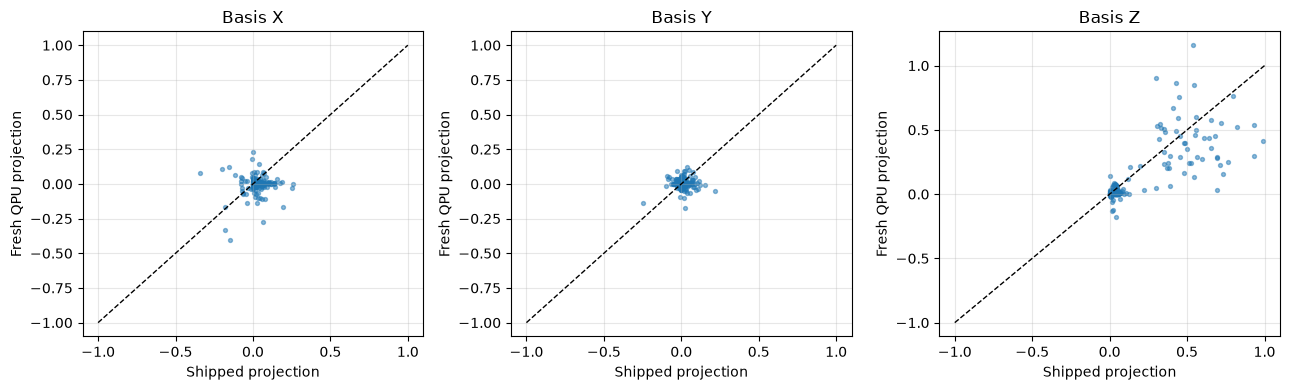

In [35]:
# OUR ADDITION: compare fresh QPU projections with the shipped ones
if not QPU_FILE.exists():
    print("No QPU run saved yet, skipping this analysis.")
else:
    saved = np.load(QPU_FILE)
    rows = saved["indices"]
    fresh = saved["projections"]
    shipped = P_train[rows]
    n_used = len(rows)
    print(f"Backend: {saved['backend']}, samples compared: {n_used}, QPU seconds used: {np.nansum(saved['usage_seconds']):.1f}")

    diff = fresh - shipped
    keep = col_std_q > 0
    z_diff = diff[:, keep] / col_std_q[keep]
    rms = np.sqrt((z_diff ** 2).mean())

    print(f"Mean absolute difference (raw units):       {np.abs(diff).mean():.4f}")
    print(f"RMS difference (in column-std units):       {rms:.3f}")
    print(f"Rough noise per run (RMS / sqrt 2):         {rms / np.sqrt(2):.3f} x column std")
    print("Compare that with the Track 2B noise levels: 0.1, 0.25, 0.5, 1.0, 2.0")

    for name, start in [("X", 0), ("Y", 60), ("Z", 120)]:
        block = slice(start, start + 60)
        corr = np.corrcoef(fresh[:, block].ravel(), shipped[:, block].ravel())[0, 1]
        print(f"  basis {name}: correlation {corr:.3f}, mean abs diff {np.abs(diff[:, block]).mean():.4f}")

    # does each fresh vector land closest to its own shipped row?
    center = P_train[:, keep].mean(axis=0)
    z_all = (P_train[:, keep] - center) / col_std_q[keep]
    z_fresh = (fresh[:, keep] - center) / col_std_q[keep]
    matches = 0
    for k in range(n_used):
        dists = np.linalg.norm(z_all - z_fresh[k], axis=1)
        if np.argmin(dists) == rows[k]:
            matches += 1
    print(f"Closest shipped row is the correct one for {matches} of {n_used} samples")

    # does the trained quantum SVM treat fresh and shipped vectors the same way?
    pred_fresh = svm_quantum.predict(fresh)
    pred_shipped = svm_quantum.predict(shipped)
    print(f"Quantum SVM gives the same label on fresh and shipped vectors for {(pred_fresh == pred_shipped).sum()} of {n_used} samples")

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, (name, start) in zip(axes, [("X", 0), ("Y", 60), ("Z", 120)]):
        block = slice(start, start + 60)
        ax.scatter(shipped[:, block].ravel(), fresh[:, block].ravel(), s=8, alpha=0.5)
        ax.plot([-1, 1], [-1, 1], "k--", lw=1)
        ax.set_xlabel("Shipped projection")
        ax.set_ylabel("Fresh QPU projection")
        ax.set_title(f"Basis {name}")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / "track2d_qpu_vs_shipped.png", dpi=150, bbox_inches="tight")
    plt.show()

   Method: we planned 10 training samples (5 per class, fixed seed) but each sample used about 97 QPU seconds with IBM's settings (24 ZZ feature map repetitions, pairwise entanglement, measurement mitigation, ZNE with noise factors 1, 3 and 5, Pauli twirling). A 10-minute free budget with a 6-minute cap allowed only 4 samples, run on ibm_marrakesh. We compare the 180 values per sample with the matching rows of `projections_train.csv`.